current time: t = 0.0001
current time: t = 0.0002
current time: t = 0.00030000000000000003
current time: t = 0.0004
current time: t = 0.0005
current time: t = 0.0006000000000000001
current time: t = 0.0007000000000000001
current time: t = 0.0008000000000000001
current time: t = 0.0009000000000000002
current time: t = 0.0010000000000000002
current time: t = 0.0011000000000000003
current time: t = 0.0012000000000000003
current time: t = 0.0013000000000000004
current time: t = 0.0014000000000000004
current time: t = 0.0015000000000000005
current time: t = 0.0016000000000000005
current time: t = 0.0017000000000000006
current time: t = 0.0018000000000000006
current time: t = 0.0019000000000000006
current time: t = 0.0020000000000000005
current time: t = 0.0021000000000000003
current time: t = 0.0022
current time: t = 0.0023
current time: t = 0.0024
current time: t = 0.0024999999999999996
current time: t = 0.0025999999999999994
current time: t = 0.0026999999999999993
current time: t = 0.0027

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


current time: t = 0.4857999999999628
current time: t = 0.4858999999999628
current time: t = 0.4859999999999628
current time: t = 0.4860999999999628
current time: t = 0.4861999999999628
current time: t = 0.48629999999996276
current time: t = 0.48639999999996275
current time: t = 0.48649999999996274
current time: t = 0.48659999999996273
current time: t = 0.4866999999999627
current time: t = 0.4867999999999627
current time: t = 0.4868999999999627
current time: t = 0.4869999999999627
current time: t = 0.4870999999999627
current time: t = 0.48719999999996266
current time: t = 0.48729999999996265
current time: t = 0.48739999999996264
current time: t = 0.48749999999996263
current time: t = 0.4875999999999626
current time: t = 0.4876999999999626
current time: t = 0.4877999999999626
current time: t = 0.4878999999999626
current time: t = 0.4879999999999626
current time: t = 0.48809999999996256
current time: t = 0.48819999999996255
current time: t = 0.48829999999996254
current time: t = 0.4883999

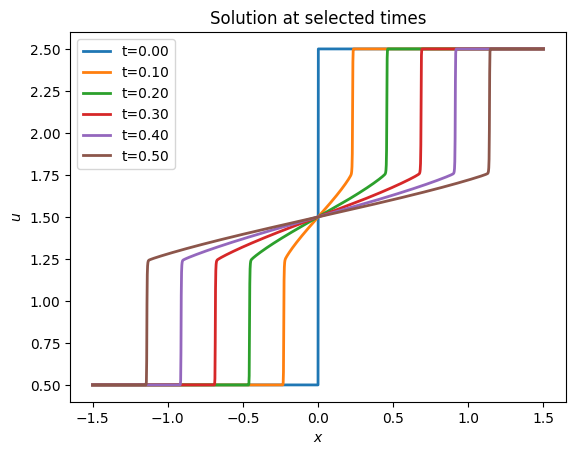

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
ul_init = 1/2
ur_init = 5/2
def u0(x):
    return np.where(x <= 0, ul_init, ur_init)

def g(u):
    return u**2

a = 0.5
def h(u):
    return u**2 + a*(1-u)**2

def f(u):
    return np.sin(np.pi*u)

def WENO(a, u, dx):
    nx = len(u)
    n_stencil = 3
    I = np.arange(n_stencil-1, nx - n_stencil)

    # Compute the values at the right-hand sides of the cell boundaries (u_{i+1/2}^-) for candidate stencils
    vmm = u[I - 2]
    vm = u[I - 1]
    v = u[I]
    vp = u[I + 1]
    vpp = u[I + 2]

    p0n = (2 * vmm - 7 * vm + 11 * v) / 6
    p1n = (-vm + 5 * v + 2 * vp) / 6
    p2n = (2 * v + 5 * vp - vpp) / 6

    # Compute the weights for candidate stencils
    B0n = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1n = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2n = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0n = 1 / 10
    d1n = 6 / 10
    d2n = 3 / 10
    epsilon = 1e-6

    alpha0n = d0n / (epsilon + np.minimum(B0n, 1e30)) ** 2
    alpha1n = d1n / (epsilon + np.minimum(B1n, 1e30)) ** 2
    alpha2n = d2n / (epsilon + np.minimum(B2n, 1e30)) ** 2
    alphasumn = alpha0n + alpha1n + alpha2n

    # ENO stencils weigths
    w0n = alpha0n / alphasumn
    w1n = alpha1n / alphasumn
    w2n = alpha2n / alphasumn

    # Numerical Flux at cell boundary (u_{i+1/2}^{-})
    hn = w0n * p0n + w1n * p1n + w2n * p2n

    # Compute the values at the right-hand side of the cell boundaries (u_{i+1/2}^+)
    vmm = u[I - 1]
    vm = u[I]
    v = u[I + 1]
    vp = u[I + 2]
    vpp = u[I + 3]

    p0p = (-vmm + 5 * vm + 2 * v) / 6
    p1p = (2 * vm + 5 * v - vp) / 6
    p2p = (11 * v - 7 * vp + 2 * vpp) / 6

    B0p = 13 / 12 * (vmm - 2 * vm + v) ** 2 + 1 / 4 * (vmm - 4 * vm + 3 * v) ** 2
    B1p = 13 / 12 * (vm - 2 * v + vp) ** 2 + 1 / 4 * (vm - vp) ** 2
    B2p = 13 / 12 * (v - 2 * vp + vpp) ** 2 + 1 / 4 * (3 * v - 4 * vp + vpp) ** 2

    d0p = 3 / 10
    d1p = 6 / 10
    d2p = 1 / 10
    epsilon = 1e-6

    alpha0p = d0p / (epsilon + np.minimum(B0p, 1e30)) ** 2
    alpha1p = d1p / (epsilon + np.minimum(B1p, 1e30)) ** 2
    alpha2p = d2p / (epsilon + np.minimum(B2p, 1e30)) ** 2
    alphasump = alpha0p + alpha1p + alpha2p

    # ENO stencils weigths
    w0p = alpha0p / alphasump
    w1p = alpha1p / alphasump
    w2p = alpha2p / alphasump

    # Numerical Flux at cell boundary (u_{i+1/2}^{+})
    hp = w0p * p0p + w1p * p1p + w2p * p2p

    LF = np.zeros_like(u)
    res = np.zeros_like(u)

    LF[I] = 0.5 * (f(hn) + f(hp) - abs(a) * (hp - hn)) # Lax-friedrichs flux

    res[I] = (LF[I] - LF[I - 1]) / dx     # L = -df(u) / dx

    return res

if __name__ == "__main__":
    T = 0.5
    CFL = 0.5
    N = 1500
    xl = -1.5
    xr = 1.5
    dx = (xr - xl) / N
    nx = N + 1
    ul = ul_init
    ur = ur_init
    
    x = np.linspace(xl, xr, nx)
    xg = np.concatenate((np.array([xl - 2 * dx, xl - dx]), x, np.array([xr + dx, xr + 2 * dx])))
    nxg = len(xg)

    ut0 = u0(xg)
    lambda0 = np.max(ut0**2)
    dt0 = CFL * dx / lambda0
    lbd = lambda0
    # dt = dt0
    dt = 0.05*dx
    u = ut0
    t = 0

    res = [ut0.copy()]
    times = [0.0]
    iter = 0
    while t < T:
        if t + dt > T: dt = T - t
        t = t + dt

        uo = u
        L = WENO(lbd, u, dx)
        u = uo - dt * L

        # Enforce Dirichlet BC: set boundary points
        u[2] = ul
        u[nxg - 3] = ur
        # Set ghost cells (constant extension)
        u[0] = ul
        u[1] = ul
        u[-1] = ur
        u[-2] = ur

        L = WENO(lbd, u, dx)
        u = 0.75 * uo + 0.25 * (u - dt * L)

        # Enforce again
        u[2] = ul
        u[nxg - 3] = ur
        u[0] = ul
        u[1] = ul
        u[-1] = ur
        u[-2] = ur

        L = WENO(lbd, u, dx)
        u = (uo + 2 * (u - dt * L)) / 3

        # Enforce again
        u[2] = ul
        u[nxg - 3] = ur
        u[0] = ul
        u[1] = ul
        u[-1] = ur
        u[-2] = ur

        lbd = np.max(u**2)
        # dt = CFL * dx / lbd

        res.append(u.copy())
        times.append(t)
        iter = iter + 1

        print("current time: t = {}".format(t))


    res = np.stack(res)

    # Save the solutions (all time steps, excluding ghosts) to a file
    np.savez('Results/sin_flux_HCL_ref.npz', times=times[::5], x=x, u=res[::5, 2:nxg-2])

    # Plot at t=0, 0.25, 0.5 (using closest available time steps)
    fig, ax = plt.subplots()
    desired_times = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
    times_array = np.array(times)
    for des in desired_times:
        i = np.argmin(np.abs(times_array - des))
        ax.plot(x, res[i, 2:nxg-2], label=f't={times[i]:.2f}', linewidth=2)
    ax.legend()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$u$')
    plt.title('Solution at selected times')
    plt.savefig('Results/sin_flux_HCL_plot.eps')
    plt.show()

In [5]:
data = np.load('Results/sin_flux_HCL_ref.npz')
times = data['times']
x = data['x']
u_num = data['u']  # Shape: (n_times, n_x)

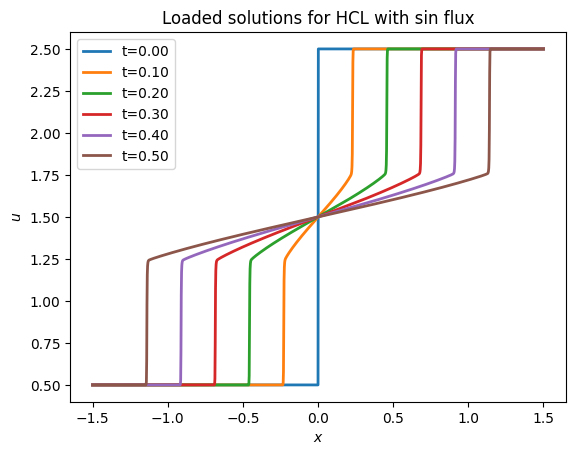

In [6]:
# Example: Plot solutions at specific times
desired_times = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
fig, ax = plt.subplots()
for des in desired_times:
    i = np.argmin(np.abs(times - des))  # Find index of closest time
    ax.plot(x, u_num[i], label=f't={times[i]:.2f}', linewidth=2)
ax.legend()
plt.xlabel(r'$x$')
plt.ylabel(r'$u$')
plt.title('Loaded solutions for HCL with sin flux')
plt.show()

In [7]:
times.shape

(1001,)

In [8]:
u_num.shape

(1001, 1501)